In [1]:
import sklearn
import pandas as pd
import matplotlib.pyplot as plt
import sklearn.linear_model as lm
import sklearn.pipeline as pipe
import sklearn.preprocessing as pp
import sklearn.model_selection as ms
import sklearn.neighbors as n
import numpy as np
import sklearn.ensemble as rf
import tensorflow as tf
import keras

In [2]:
data = np.load("data/mnist/mnist.npz")
print(data)
xtrain = data["x_train"]
xtest = data["x_test"]
ytrain = data["y_train"]
ytest = data["y_test"]

NpzFile 'data/mnist/mnist.npz' with keys: x_test, x_train, y_train, y_test


In [3]:
xtrain = xtrain.reshape(-1, 28*28)
xtest = xtest.reshape(-1, 28*28)

In [4]:
ytrain = keras.utils.to_categorical(ytrain)
ytest = keras.utils.to_categorical(ytest)
ytrain.shape

(60000, 10)

In [5]:
model = keras.Sequential()
model.add(keras.layers.Input((xtrain.shape[1],)))
model.add(keras.layers.Dense(800, activation="relu"))
model.add(keras.layers.Dropout(0.1))
model.add(keras.layers.Dense(500, activation="relu"))
model.add(keras.layers.Dropout(0.1))
model.add(keras.layers.Dense(200, activation="relu"))
model.add(keras.layers.Dropout(0.1))
model.add(keras.layers.Dense(10, activation="softmax"))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 800)                 │         628,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 800)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 500)                 │         400,500 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 500)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 200)                 │         100,200 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 200)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │           2,010 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,130,710 (4.31 MB)

 Trainable params: 1,130,710 (4.31 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
model.compile(loss="categorical_crossentropy", metrics=["accuracy"])
model.fit(xtrain, ytrain, epochs=10, validation_split=0.2, batch_size=100)


Epoch 1/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8982 - loss: 0.5843 - val_accuracy: 0.9415 - val_loss: 0.5469
Epoch 2/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9091 - loss: 0.5633 - val_accuracy: 0.9321 - val_loss: 0.6095
Epoch 3/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9081 - loss: 0.5441 - val_accuracy: 0.9290 - val_loss: 0.5953
Epoch 4/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9024 - loss: 0.6046 - val_accuracy: 0.9364 - val_loss: 0.7756
Epoch 5/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8991 - loss: 0.6615 - val_accuracy: 0.9247 - val_loss: 1.1350
Epoch 6/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8971 - loss: 0.6191 - val_accuracy: 0.8813 - val_loss: 0.6779
Epoch 7/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8985 - loss: 0.5834 - val_accuracy: 0.9203 - val_loss: 0.9522
Epoch 8/10
480/480 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8999 - loss: 0.6503 - val_accuracy: 0.

In [24]:
model.evaluate(xtest, ytest)

ValueError: Exception encountered when calling Sequential.call().

[1mInvalid input shape for input Tensor("sequential_1/Cast:0", shape=(None, 28, 28), dtype=float32) with name 'keras_tensor' and path ''. Expected shape (None, 784), but input has incompatible shape (None, 28, 28)[0m

Arguments received by Sequential.call():
  • inputs=tf.Tensor(shape=(None, 28, 28), dtype=uint8)
  • training=False
  • mask=None
  • kwargs=<class 'inspect._empty'>

In [8]:
model.save("data/mnist/mlp.h5")

In [15]:
ypred = np.argmax(model.predict(xtest), axis=1)
xtest.shape, ypred

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 907us/step


((10000, 784), array([7, 2, 1, ..., 4, 5, 6], shape=(10000,)))

In [16]:
select = np.random.randint(xtest.shape[0], size=12)
xtest = xtest.reshape(-1, 28, 28)

In [18]:
ytest = data["y_test"]
errors = ytest != ypred
xerrors = xtest[errors]
yerrors = ypred[errors]
yerrors

array([8, 0, 8, 6, 4, 4, 8, 0, 7, 6, 8, 6, 0, 4, 6, 7, 3, 8, 4, 7, 0, 0,
       8, 5, 9, 6, 9, 6, 6, 2, 5, 6, 8, 9, 6, 8, 8, 8, 9, 4, 9, 6, 5, 9,
       9, 5, 5, 3, 0, 5, 8, 9, 1, 4, 2, 0, 2, 8, 5, 6, 8, 9, 8, 2, 8, 6,
       8, 7, 1, 9, 6, 2, 5, 4, 9, 4, 3, 6, 7, 8, 2, 4, 0, 8, 8, 0, 1, 8,
       6, 1, 9, 7, 4, 3, 6, 1, 9, 6, 4, 2, 6, 3, 6, 8, 8, 9, 1, 9, 5, 8,
       3, 7, 6, 3, 4, 8, 9, 9, 2, 6, 6, 0, 8, 7, 8, 7, 3, 3, 1, 0, 2, 9,
       8, 2, 6, 4, 8, 0, 9, 9, 4, 2, 8, 8, 8, 2, 9, 0, 9, 9, 9, 3, 8, 8,
       7, 4, 9, 9, 0, 8, 8, 8, 5, 9, 8, 9, 1, 8, 2, 6, 6, 0, 1, 1, 9, 6,
       6, 0, 8, 6, 8, 8, 9, 1, 8, 8, 9, 8, 8, 4, 9, 2, 1, 6, 0, 1, 8, 8,
       2, 4, 8, 9, 0, 3, 2, 5, 8, 6, 9, 5, 1, 9, 5, 7, 2, 3, 6, 9, 3, 4,
       3, 2, 7, 9, 7, 9, 6, 6, 8, 9, 1, 9, 4, 8, 6, 8, 3, 5, 1, 8, 1, 3,
       8, 6, 3, 2, 3, 9, 4, 9, 2, 3, 8, 2, 8, 6, 3, 1, 8, 6, 3, 1, 2, 0,
       4, 6, 2, 3, 6, 8, 3, 3, 4, 4, 8, 9, 8, 8, 3, 3, 9, 3, 8, 6, 4, 8,
       0, 8, 9, 9, 8, 2, 3, 7, 8, 3, 4, 3, 7, 7, 8,

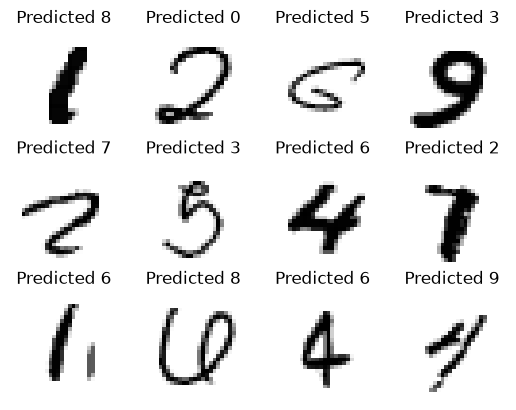

In [19]:
select = np.random.randint(xerrors.shape[0], size=12)
for index, value in enumerate(select):
    plt.subplot(3,4, index + 1)
    plt.axis("off")
    plt.imshow(xerrors[value], cmap=plt.cm.gray_r)
    plt.title(f"Predicted {yerrors[value]}")
plt.show()